### Utility Libraries

In [ ]:
!pip install -q timm albumentations
!pip install torchmetrics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 90.3 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cudf-cu12 26.2.1 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 whic

In [ ]:
import kagglehub
import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
import gc
import cv2
import timm
import random
import re

from tqdm import tqdm
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
import albumentations as A
import torch.nn.functional as F
from albumentations.pytorch import ToTensorV2
from torchmetrics.classification import BinaryAUROC, BinaryAccuracy
from torch.amp import GradScaler, autocast

# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


### Kaggle Login (For Colab Only)

In [ ]:
# kagglehub.login()

In [ ]:
# os.environ['KAGGLEHUB_CACHE'] = "./data"
path = "/kaggle/input/competitions/multimodal-cancer-classification-challenge-2026"


### Data Exploration

Visualizing samples with labels from train.csv:


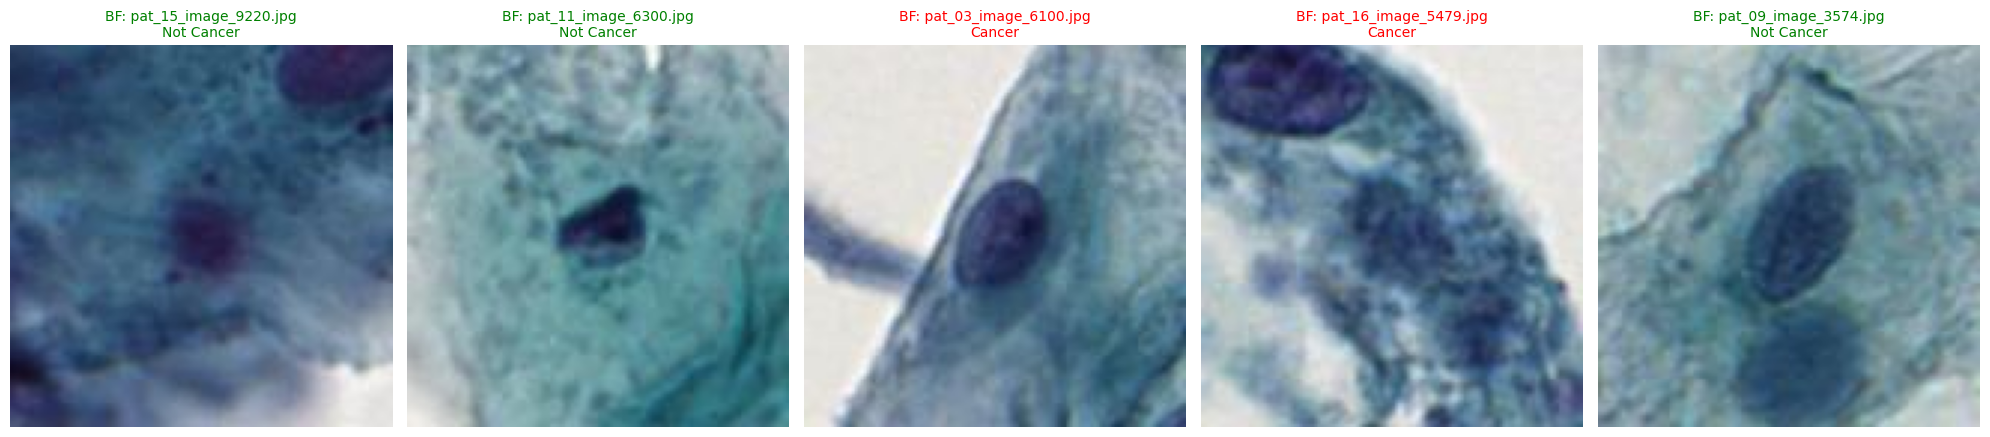

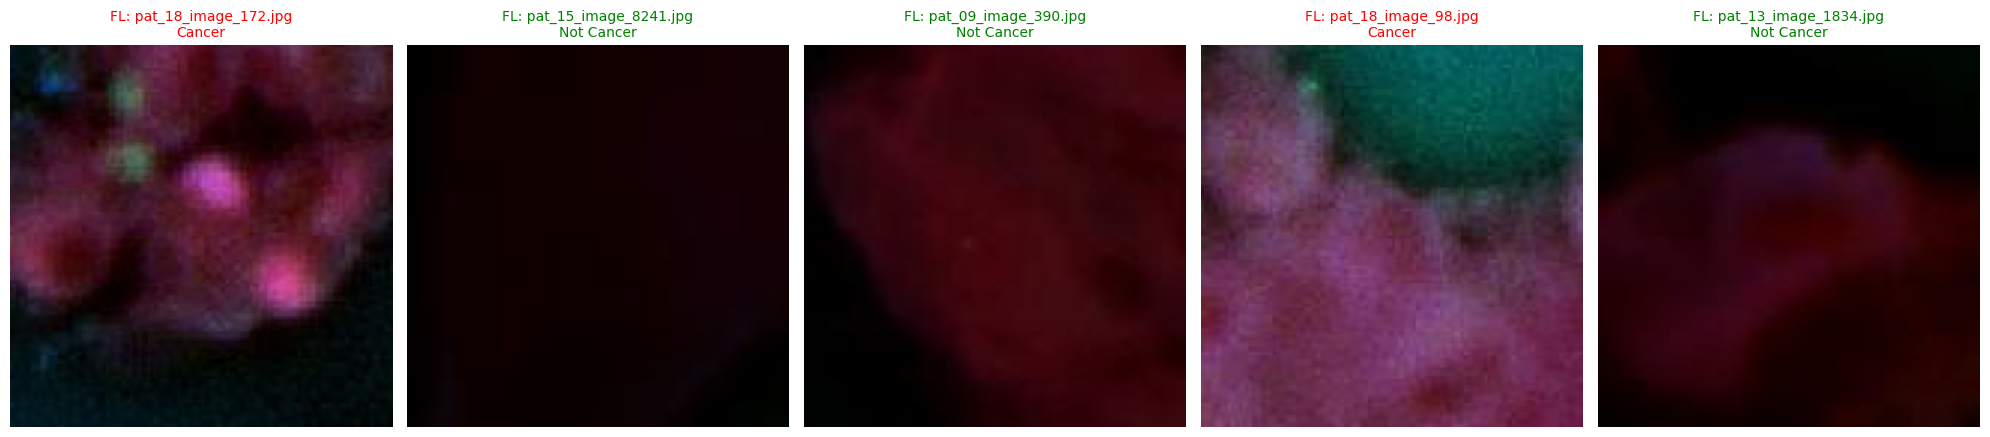

In [ ]:
# Load the latest labels from the competition directory
labels_path = os.path.join(path, 'train.csv')
train_df = pd.read_csv(labels_path)

# Define paths for Bright Field and Fluorescence training images
BF_Images = os.path.join(path, 'BF', 'train')
FL_Images = os.path.join(path, 'FL', 'train')

# Mapping for human-readable titles
diagnosis_map = {0: 'Not Cancer', 1: 'Cancer'}

# Get lists of available image files
BF_Images_list = [f for f in os.listdir(BF_Images) if f.lower().endswith(('.jpg'))]
FL_Images_list = [f for f in os.listdir(FL_Images) if f.lower().endswith(('.jpg'))]

random.shuffle(BF_Images_list)
random.shuffle(FL_Images_list)

def plot_labeled_samples(img_list, base_path, title_prefix):
    fig, ax = plt.subplots(1, 5, figsize=(20, 5))
    for i in range(5):
        img_name = img_list[i]
        img_path = os.path.join(base_path, img_name)
        img = cv2.imread(img_path)

        # Search for the diagnosis in the train_df based on filename
        match = train_df[train_df['Name'] == img_name]
        if not match.empty:
            label_val = match.iloc[0]['Diagnosis']
            label_text = diagnosis_map.get(label_val, 'Unknown')
        else:
            label_text = "Not Found in CSV"

        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax[i].imshow(img)
            title_color = 'red' if label_text == 'Cancer' else 'green' if label_text == 'Not Cancer' else 'black'
            ax[i].set_title(f"{title_prefix}: {img_name}\n{label_text}", color=title_color, fontsize=10)
        ax[i].axis("off")
    plt.tight_layout()
    plt.show()

print("Visualizing samples with labels from train.csv:")
plot_labeled_samples(BF_Images_list, BF_Images, "BF")
plot_labeled_samples(FL_Images_list, FL_Images, "FL")

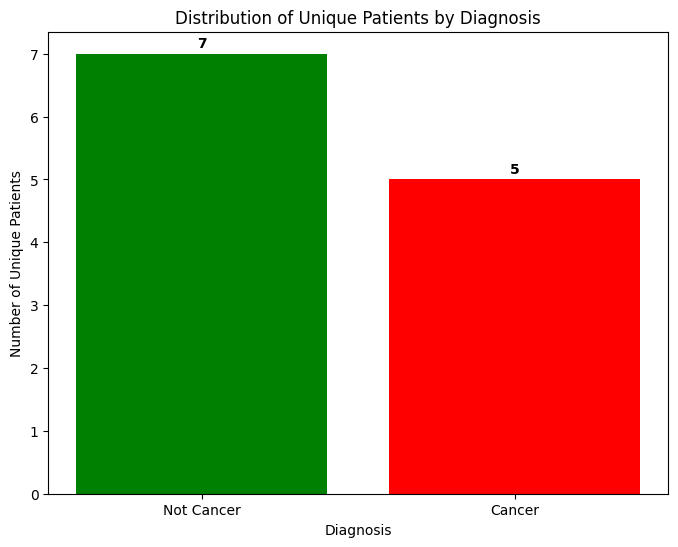

Total unique patients: 12


In [ ]:
# Using train_df consistently for data exploration
# Pattern assumes 'pat_XX_image_YY.jpg'
train_df['Patient'] = train_df['Name'].apply(lambda x: re.match(r'(pat_\d+)', x).group(1))

# Get the diagnosis per patient
patient_diagnosis = train_df.groupby('Patient')['Diagnosis'].first().reset_index()

# Count the number of patients for each diagnosis
diagnosis_counts = patient_diagnosis['Diagnosis'].value_counts().sort_index()

# Plotting
plt.figure(figsize=(8, 6))
colors = ['green', 'red']
labels_map = {0: 'Not Cancer', 1: 'Cancer'}
diagnosis_names = [labels_map[i] for i in diagnosis_counts.index]

plt.bar(diagnosis_names, diagnosis_counts.values, color=colors[:len(diagnosis_counts)])
plt.xlabel('Diagnosis')
plt.ylabel('Number of Unique Patients')
plt.title('Distribution of Unique Patients by Diagnosis')

for i, count in enumerate(diagnosis_counts.values):
    plt.text(i, count + 0.1, str(count), ha='center', fontweight='bold')

plt.show()

print(f"Total unique patients: {len(patient_diagnosis)}")

In [ ]:
num_patients = train_df['Patient'].nunique()
print(f"There are {num_patients} unique patients in the dataset.")

There are 12 unique patients in the dataset.


In [ ]:
# Load the labels and setup paths immediately after downloading
labels_path = os.path.join(path, 'train.csv')
train_df = pd.read_csv(labels_path)

# Extract Patient ID immediately to ensure consistency across all downstream tasks
train_df['Patient'] = train_df['Name'].apply(lambda x: re.match(r'(pat_\d+)', x).group(1))

BF_Images = os.path.join(path, 'BF', 'train')
FL_Images = os.path.join(path, 'FL', 'train')
diagnosis_map = {0: 'Not Cancer', 1: 'Cancer'}

print(f"Loaded {len(train_df)} samples and extracted patient IDs.")

Loaded 114302 samples and extracted patient IDs.


### Group K-Fold

In [ ]:
# # Initialize GroupKFold based on the Patient ID column created in the loading step
# gkf = GroupKFold(n_splits=4)
# train_df['fold'] = -1

# for fold, (train_idx, val_idx) in enumerate(gkf.split(train_df, train_df['Diagnosis'], groups=train_df['Patient'])):
#     train_df.loc[val_idx, 'fold'] = fold

# print(f"Fold distribution:\n{train_df['fold'].value_counts()}")
# print(f"Unique patients per fold check:\n{train_df.groupby('fold')['Patient'].nunique()}")

Fold distribution:
fold
2    30000
1    30000
0    30000
3    24302
Name: count, dtype: int64
Unique patients per fold check:
fold
0    3
1    3
2    3
3    3
Name: Patient, dtype: int64


### Stratified K-Fold

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Initialize StratifiedGroupKFold to maintain diagnosis ratio while keeping patients together
# Increasing splits to 6 gives the algorithm more mathematical room to balance 12 patients
sgkf = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
train_df['fold'] = -1

# We use 'Diagnosis' as the target for stratification and 'Patient' as the group
for fold, (train_idx, val_idx) in enumerate(sgkf.split(train_df, train_df['Diagnosis'], groups=train_df['Patient'])):
    train_df.loc[val_idx, 'fold'] = fold

print(f"Fold distribution:\n{train_df['fold'].value_counts()}")
print(f"\nUnique patients per fold:\n{train_df.groupby('fold')['Patient'].nunique()}")
print(f"\nDiagnosis ratio per fold (Target mean):\n{train_df.groupby('fold')['Diagnosis'].mean()}")

Fold distribution:
fold
0    40000
2    40000
1    34302
Name: count, dtype: int64

Unique patients per fold:
fold
0    4
1    4
2    4
Name: Patient, dtype: int64

Diagnosis ratio per fold (Target mean):
fold
0    0.500000
1    0.416944
2    0.250000
Name: Diagnosis, dtype: float64


In [ ]:
import pandas as pd

# Ensure we use train_df which contains the patient and fold info
if 'train_df' in globals() and 'fold' in train_df.columns:
    df_to_check = train_df
else:
    df_to_check = None

if df_to_check is not None:
    # Check if each patient belongs to only one fold
    patient_fold_counts = df_to_check.groupby('Patient')['fold'].nunique()
    is_valid_split = (patient_fold_counts == 1).all()
    print(f"Is every patient assigned to exactly one fold? {is_valid_split}")

    # Display the mapping of Patient to Fold
    patient_to_fold = df_to_check.groupby(['Patient', 'fold']).size().reset_index(name='Image_Count')
    display(patient_to_fold.head())

    # Summary of how many patients are in each fold
    fold_summary = patient_to_fold.groupby('fold')['Patient'].count()
    print('\nNumber of patients per fold:')
    print(fold_summary)
else:
    print('Error: Could not find train_df with fold assignments. Please ensure the GroupKFold cell has been executed.')

Is every patient assigned to exactly one fold? True


,Patient,fold,Image_Count
0,pat_03,0,10000
1,pat_05,1,4302
2,pat_07,2,10000
3,pat_09,0,10000
4,pat_10,1,10000



Number of patients per fold:
fold
0    4
1    4
2    4
Name: Patient, dtype: int64


In [ ]:
import pandas as pd

# Ensure we use the labels dataframe which has the patient and fold info
if 'labels' in globals() and 'fold' in labels.columns:
    df_to_check = labels
elif 'train_df' in globals() and 'fold' in train_df.columns:
    df_to_check = train_df
else:
    df_to_check = None

if df_to_check is not None:
    # Check if each patient belongs to only one fold
    patient_fold_counts = df_to_check.groupby('Patient')['fold'].nunique()
    is_valid_split = (patient_fold_counts == 1).all()

    # print(f"Is every patient assigned to exactly one fold? {is_valid_split}")

    # Display the mapping of Patient to Fold
    patient_to_fold = df_to_check.groupby(['Patient', 'fold']).size().reset_index(name='Image_Count')
    display(patient_to_fold)

    # Summary of how many patients are in each fold
    fold_summary = patient_to_fold.groupby('fold')['Patient'].count()
    print('\nNumber of patients per fold:')
    print(fold_summary)
else:
    print('Error: Could not find a dataframe with fold assignments. Please ensure the GroupKFold cell has been executed.')

,Patient,fold,Image_Count
0,pat_03,0,10000
1,pat_05,1,4302
2,pat_07,2,10000
3,pat_09,0,10000
4,pat_10,1,10000
5,pat_11,2,10000
6,pat_13,2,10000
7,pat_14,0,10000
8,pat_15,1,10000
9,pat_16,2,10000



Number of patients per fold:
fold
0    4
1    4
2    4
Name: Patient, dtype: int64


In [ ]:
# Calculate total image counts for each diagnosis
cancer_images = len(train_df[train_df['Diagnosis'] == 1])
not_cancer_images = len(train_df[train_df['Diagnosis'] == 0])

print(f"Total images with Cancer: {cancer_images}")
print(f"Total images with Not Cancer: {not_cancer_images}")
print(f"Grand Total: {len(train_df)}")

Total images with Cancer: 44302
Total images with Not Cancer: 70000
Grand Total: 114302


### Fix the Dataset Loading (hiding the corrupted images)

In [ ]:
def robust_imread(path):
    """Opens an image with PIL to avoid 'Corrupt JPEG' warnings and converts to RGB NumPy array."""
    try:
        with Image.open(path) as img:
            img = img.convert('RGB')
            return np.array(img)
    except Exception as e:
        print(f"Error loading {path}: {e}")
        return None

# To fix the issue in your Dataset class, replace cv2.imread and cv2.cvtColor with robust_imread

### Data Loader

In [ ]:
class MultimodalCancerDataset(Dataset):
    def __init__(self, df, bf_dir, fl_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.bf_dir = bf_dir
        self.fl_dir = fl_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'Name']
        label = torch.tensor(self.df.loc[idx, 'Diagnosis'], dtype=torch.float32)

        # Use robust_imread (defined in the previous cell) to avoid JPEG header warnings
        bf_img = robust_imread(os.path.join(self.bf_dir, img_name))
        fl_img = robust_imread(os.path.join(self.fl_dir, img_name))

        if bf_img is None or fl_img is None:
             # Safety fallback to zeros if an image fails to load entirely
             bf_img = np.zeros((224, 224, 3), dtype=np.uint8)
             fl_img = np.zeros((224, 224, 3), dtype=np.uint8)

        if self.transform:
            augmented = self.transform(image=bf_img, image_fl=fl_img)
            return augmented['image'], augmented['image_fl'], label

        bf_tensor = torch.from_numpy(bf_img).permute(2, 0, 1).float() / 255.0
        fl_tensor = torch.from_numpy(fl_img).permute(2, 0, 1).float() / 255.0
        return bf_tensor, fl_tensor, label

### Augmentations

In [ ]:
train_transform = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    # A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=45, p=0.5),
    # A.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.1, p=0.5),
    A.Affine(scale=(0.8, 1.2), translate_percent=(-0.1, 0.1), shear=(-10, 10), p=0.5),
    # A.OneOf([
    #     A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2),
    #     A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=10),
    # ], p=0.4),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)), # 3-channel
    ToTensorV2(),
], additional_targets={'image_fl': 'image'}) # Sync transformations

val_transform = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)), # 3-channel
    ToTensorV2(),
], additional_targets={'image_fl': 'image'}) # Sync transformations

train_ds = MultimodalCancerDataset(train_df[train_df['fold'] != 0], BF_Images, FL_Images, transform=train_transform)
valid_ds = MultimodalCancerDataset(train_df[train_df['fold'] == 0], BF_Images, FL_Images, transform=val_transform)

# Optimization: Increase num_workers and use pin_memory for faster GPU transfer
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_ds, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train dataset size: {len(train_ds)}")
print(f"Validation dataset size: {len(valid_ds)}")

Train dataset size: 74302
Validation dataset size: 40000


### ConvNeXt Model (Single)

In [ ]:
class MultimodalConvNeXt(nn.Module):
    def __init__(self, backbone_name='convnextv2_tiny.fcmae_ft_in22k_in1k', pretrained=True):
        super(MultimodalConvNeXt, self).__init__()
        # Load backbone without the classifier head
        self.model = timm.create_model(backbone_name, pretrained=pretrained, num_classes=0)

        # 1. Modify the Stem to accept 6 channels (3 BF + 3 FL)
        # ConvNeXt uses a patch_embed stem which is essentially a Conv2d
        old_stem = self.model.stem[0]
        self.model.stem[0] = nn.Conv2d(6, old_stem.out_channels,
                                       kernel_size=old_stem.kernel_size,
                                       stride=old_stem.stride,
                                       padding=old_stem.padding)

        # Initialize new stem weights
        if pretrained:
            with torch.no_grad():
                # Copy pretrained weights to both halves of the new 6-channel input
                self.model.stem[0].weight[:, :3, :, :] = old_stem.weight
                self.model.stem[0].weight[:, 3:, :, :] = old_stem.weight

        # 2. Custom Classification Head
        embed_dim = self.model.num_features
        self.head = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Dropout(0.2),
            nn.Linear(embed_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, 1)
        )

        # 3. Strategic Freezing: Freeze early stages, keep stem and final stages trainable
        for name, param in self.model.named_parameters():
            if 'stem' in name or 'stages.3' in name:
                param.requires_grad = True
            else:
                param.requires_grad = False

    def forward(self, x):
        features = self.model(x)
        return self.head(features)

In [ ]:
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
# Initialize the ConvNeXt model
model_convnext = MultimodalConvNeXt(pretrained=True).to(device)
print("Multimodal ConvNeXt model initialized.")

# Quick test with a dummy batch
# dummy_input = torch.randn(1, 6, 224, 224).to(device)
# with torch.no_grad():
#     output = model_convnext(dummy_input)
# print(f"Output shape: {output.shape}")

Multimodal ConvNeXt model initialized.


### ConvNeXt Dual

In [ ]:
# class DualConvNeXtFusion(nn.Module):
#     def __init__(self, backbone_name='convnextv2_tiny.fcmae_ft_in22k_in1k', pretrained=True):
#         super(DualConvNeXtFusion, self).__init__()

#         # Twin Encoders: One for BF, one for FL
#         # We use num_classes=0 to get the feature vector before the original head
#         self.encoder_bf = timm.create_model(backbone_name, pretrained=pretrained, num_classes=0)
#         self.encoder_fl = timm.create_model(backbone_name, pretrained=pretrained, num_classes=0)

#         # The feature dimension for convnextv2_tiny is 768
#         feat_dim = self.encoder_bf.num_features

#         # Fusion Head: Processes the concatenated features (768 * 2 = 1536)
#         self.head = nn.Sequential(
#             nn.LayerNorm(feat_dim * 2),
#             nn.Dropout(0.4),
#             nn.Linear(feat_dim * 2, 512),
#             nn.GELU(),
#             nn.BatchNorm1d(512),
#             nn.Dropout(0.3),
#             nn.Linear(512, 1)
#         )

#         # Strategic freezing: Freeze early stages of both backbones
#         for model in [self.encoder_bf, self.encoder_fl]:
#             for name, param in model.named_parameters():
#                 if 'stages.3' in name or 'norm' in name:
#                     param.requires_grad = True
#                 else:
#                     param.requires_grad = False

#     def forward(self, bf, fl):
#         # Extract features from both modalities
#         feat_bf = self.encoder_bf(bf) # Shape: [batch, 768]
#         feat_fl = self.encoder_fl(fl) # Shape: [batch, 768]

#         # Concatenate on the feature dimension
#         fused_features = torch.cat([feat_bf, feat_fl], dim=1) # Shape: [batch, 1536]

#         return self.head(fused_features)

In [ ]:
# # Initialize the Dual-Stream Model
# model_dual_convnext = DualConvNeXtFusion(pretrained=True).to(device)
# print("Dual-Stream ConvNeXt model initialized.")

# # Quick test with separate dummy tensors (3 channels each)
# # Increased batch size to 2 to satisfy BatchNorm requirements
# dummy_bf = torch.randn(2, 3, 224, 224).to(device)
# dummy_fl = torch.randn(2, 3, 224, 224).to(device)

# with torch.no_grad():
#     output = model_dual_convnext(dummy_bf, dummy_fl)

# print(f"Output shape: {output.shape}")

Dual-Stream ConvNeXt model initialized.
Output shape: torch.Size([2, 1])


### Training and Validation Function (with MixUp)

In [ ]:
# --- Helper Function: Mixup Implementation for Single Stream (6-channel) ---
def mixup_data(x, y, alpha=0.2):
    lam = torch.distributions.beta.Beta(alpha, alpha).sample().to(x.device)
    batch_size = x.size()[0]
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def train_one_epoch(model, loader, optimizer, criterion, device, scaler, use_mixup=True):
    model.train()
    total_loss = 0
    auroc_metric = BinaryAUROC().to(device)
    auroc_metric.reset()

    for bf_imgs, fl_imgs, labels in tqdm(loader, desc="Training"):
        # Concatenate BF and FL images along the channel dimension (dim=1) to create 6 channels
        images = torch.cat([bf_imgs, fl_imgs], dim=1).to(device)
        labels = labels.to(device).float().view(-1, 1)

        if use_mixup:
            images, targets_a, targets_b, lam = mixup_data(images, labels)

        optimizer.zero_grad()
        with autocast("cuda"):
            # Pass only the single 'images' tensor to the single-stream model
            outputs = model(images)
            smoothing = 0.1
            if use_mixup:
                loss = lam * F.binary_cross_entropy_with_logits(outputs, targets_a * (1-smoothing) + 0.5*smoothing) + \
                       (1 - lam) * F.binary_cross_entropy_with_logits(outputs, targets_b * (1-smoothing) + 0.5*smoothing)
            else:
                loss = F.binary_cross_entropy_with_logits(outputs, labels * (1 - smoothing) + 0.5 * smoothing)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        auroc_metric.update(torch.sigmoid(outputs), labels.int())

    return total_loss / len(loader), auroc_metric.compute().item()

def validate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    auroc_metric = BinaryAUROC().to(device)
    acc_metric = BinaryAccuracy().to(device)
    auroc_metric.reset()
    acc_metric.reset()

    with torch.no_grad():
        for bf_imgs, fl_imgs, labels in tqdm(loader, desc="Validation"):
            # Concatenate for single-stream input
            images = torch.cat([bf_imgs, fl_imgs], dim=1).to(device)
            labels = labels.to(device).float().view(-1, 1)

            with autocast("cuda"):
                # Pass only the single 'images' tensor
                outputs = model(images)
                loss = criterion(outputs, labels)

            total_loss += loss.item()
            probs = torch.sigmoid(outputs)
            auroc_metric.update(probs, labels.int())
            acc_metric.update(probs, labels.int())

    return total_loss / len(loader), auroc_metric.compute().item(), acc_metric.compute().item()

### Train Single (Old)

In [ ]:
# torch.manual_seed(42)
# np.random.seed(42)
# random.seed(42)

# # --- Updated Configuration for Class Imbalance ---
# # Ratio of Negatives (70000) to Positives (44302)
# pos_count = train_df[train_df['Diagnosis'] == 1].shape[0]
# neg_count = train_df[train_df['Diagnosis'] == 0].shape[0]
# calculated_pos_weight = torch.tensor([neg_count / pos_count]).to(device)

# EPOCHS = 25
# LEARNING_RATE = 1e-5
# WEIGHT_DECAY = 5e-2
# EARLY_STOPPING_PATIENCE = 5

# print(f"Calculated pos_weight: {calculated_pos_weight.item():.4f}")

# # --- Setup ---
# trainable_params = filter(lambda p: p.requires_grad, model_convnext.parameters())
# optimizer = AdamW(trainable_params, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
# scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

# # Updated criterion with the specific pos_weight
# criterion = nn.BCEWithLogitsLoss(pos_weight=calculated_pos_weight)
# scaler = GradScaler("cuda")

# # --- Tracking ---
# history = {'train_loss': [], 'train_auc': [], 'val_loss': [], 'val_auc': [], 'val_acc': []}
# best_val_auc = 0
# early_stopping_counter = 0

# print("Starting training with optimized pos_weight to handle class imbalance...")

Calculated pos_weight: 1.5801
Starting training with optimized pos_weight to handle class imbalance...


In [ ]:
# # Execute the training loop with the updated pos_weight
# for epoch in range(EPOCHS):
#     train_loss, train_auc = train_one_epoch(
#         model_convnext, train_loader, optimizer, criterion, device, scaler
#     )

#     val_loss, val_auc, val_acc = validate(
#         model_convnext, valid_loader, criterion, device
#     )

#     scheduler.step(val_auc)

#     history['train_loss'].append(train_loss)
#     history['train_auc'].append(train_auc)
#     history['val_loss'].append(val_loss)
#     history['val_auc'].append(val_auc)
#     history['val_acc'].append(val_acc)

#     print(f"\nEpoch {epoch+1}/{EPOCHS}")
#     print(f"Train Loss: {train_loss:.4f} | Train AUC: {train_auc:.4f}")
#     print(f"Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f} | Val Acc: {val_acc:.4f}")

#     if val_auc > best_val_auc:
#         best_val_auc = val_auc
#         torch.save(model_convnext.state_dict(), 'best_convnext_balanced.pth')
#         print("*** Best Model Saved (Balanced Weights) ***")
#         early_stopping_counter = 0
#     else:
#         early_stopping_counter += 1
#         print(f"No improvement for {early_stopping_counter} epochs.")

#     if early_stopping_counter >= EARLY_STOPPING_PATIENCE:
#         print(f"Early stopping triggered at epoch {epoch+1}. Best Val AUC: {best_val_auc:.4f}")
#         break

Validation: 100%|██████████| 938/938 [03:36<00:00,  4.33it/s]



Epoch 1/25
Train Loss: 0.5702 | Train AUC: 0.6704
Val Loss: 0.5132 | Val AUC: 0.9173 | Val Acc: 0.7790
*** Best Model Saved (Balanced Weights) ***


Training:  44%|████▍     | 1161/2635 [05:50<07:29,  3.28it/s]

In [ ]:
### Training with different data folds
EPOCHS = 25
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 5e-2
EARLY_STOPPING_PATIENCE = 5
# Store overall cross-validation metrics across all folds
cv_results = {'fold_auc': [], 'fold_acc': []}

# We iterate over our 3 newly balanced folds (0, 1, 2)
for current_fold in range(3):
    print("\n" + "="*50)
    print(f"TRAINING FOLD {current_fold}")
    print("="*50)

    # 1. Reset Global Seeds for reproducible fold initializations
    torch.manual_seed(42)
    np.random.seed(42)
    random.seed(42)

    # 2. Slice dataframe into fold-specific train and validation splits
    fold_train_df = train_df[train_df['fold'] != current_fold].reset_index(drop=True)
    fold_val_df = train_df[train_df['fold'] == current_fold].reset_index(drop=True)

    # 3. Dynamic pos_weight calculation strictly on the active fold's training subset
    pos_count = fold_train_df[fold_train_df['Diagnosis'] == 1].shape[0]
    neg_count = fold_train_df[fold_train_df['Diagnosis'] == 0].shape[0]
    calculated_pos_weight = torch.tensor([neg_count / pos_count]).to(device)
    print(f"Fold {current_fold} Training Samples: {len(fold_train_df)} | Val Samples: {len(fold_val_df)}")
    print(f"Fold {current_fold} Calculated pos_weight: {calculated_pos_weight.item():.4f}")


    # 6. Reconstruct Optimizer, Scheduler, Loss and Scaler
    trainable_params = filter(lambda p: p.requires_grad, model_convnext.parameters())
    optimizer = AdamW(trainable_params, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
    criterion = nn.BCEWithLogitsLoss(pos_weight=calculated_pos_weight)
    scaler = GradScaler("cuda")

    # Reset tracking variables for the current fold
    best_val_auc = 0
    early_stopping_counter = 0
    fold_history = {'train_loss': [], 'train_auc': [], 'val_loss': [], 'val_auc': [], 'val_acc': []}

    # 7. Execute the Epoch Training Loop
    for epoch in range(1, EPOCHS + 1):
        # Run your existing functions
        train_loss, train_auc = train_one_epoch(
            model_convnext, train_loader, optimizer, criterion, device, scaler, use_mixup=True
        )
        val_loss, val_auc, val_acc = validate(
            model_convnext, valid_loader, criterion, device
        )

        # Step the scheduler using the metric to maximize (val_auc)
        scheduler.step(val_auc)

        # Log training state updates
        fold_history['train_loss'].append(train_loss)
        fold_history['train_auc'].append(train_auc)
        fold_history['val_loss'].append(val_loss)
        fold_history['val_auc'].append(val_auc)
        fold_history['val_acc'].append(val_acc)

        print(f"Epoch [{epoch}/{EPOCHS}] -> Train Loss: {train_loss:.4f} | Train AUC: {train_auc:.4f} | "
              f"Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f} | Val Acc: {val_acc:.4f}")

        # --- Check for Model Performance Improvement ---
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            early_stopping_counter = 0
            # Save the optimal state dict file for this specific patient subset fold
            torch.save(model_convnext.state_dict(), f"best_convnext_fold_{current_fold}.pth")
            print(f" ==> New Best Val AUC ({best_val_auc:.4f}) achieved. Model Weights Saved.")
        else:
            early_stopping_counter += 1
            if early_stopping_counter >= EARLY_STOPPING_PATIENCE:
                print(f" Early Stopping triggered at Epoch {epoch}. Moving to next fold.")
                break

    # Record the maximum validation score achieved in this fold run
    cv_results['fold_auc'].append(best_val_auc)
    # Record accuracy matching the best checkpoint's epoch index position
    best_epoch_idx = np.argmax(fold_history['val_auc'])
    cv_results['fold_acc'].append(fold_history['val_acc'][best_epoch_idx])

# ----- Print the results ------ #
print("\n" + "="*50)
print("FINAL CROSS-VALIDATION METRIC EVALUATIONS")
print("="*50)
for i in range(3):
    print(f"Fold {i} -> Best Val AUC: {cv_results['fold_auc'][i]:.4f} | Val Accuracy: {cv_results['fold_acc'][i]:.4f}")
print("-"*50)
print(f"Mean Cross-Validation AUC:      {np.mean(cv_results['fold_auc']):.4f}")
print(f"Mean Cross-Validation Accuracy: {np.mean(cv_results['fold_acc']):.4f}")


TRAINING FOLD 0
Fold 0 Training Samples: 74302 | Val Samples: 40000
Fold 0 Calculated pos_weight: 2.0574


Validation: 100%|██████████| 1250/1250 [06:38<00:00,  3.13it/s]


Epoch [1/25] -> Train Loss: 0.5017 | Train AUC: 0.6897 | Val Loss: 1.0455 | Val AUC: 0.7043 | Val Acc: 0.6050
 ==> New Best Val AUC (0.7043) achieved. Model Weights Saved.


Validation: 100%|██████████| 1250/1250 [02:35<00:00,  8.06it/s]


Epoch [2/25] -> Train Loss: 0.4462 | Train AUC: 0.7332 | Val Loss: 0.9144 | Val AUC: 0.8271 | Val Acc: 0.7249
 ==> New Best Val AUC (0.8271) achieved. Model Weights Saved.


Validation: 100%|██████████| 1250/1250 [02:35<00:00,  8.02it/s]


... (5 outputs left out)

Validation: 100%|██████████| 1250/1250 [02:35<00:00,  8.04it/s]


Epoch [6/25] -> Train Loss: 0.3551 | Train AUC: 0.7664 | Val Loss: 0.5683 | Val AUC: 0.9088 | Val Acc: 0.8314
 ==> New Best Val AUC (0.9088) achieved. Model Weights Saved.


Training:  13%|█▎        | 292/2322 [01:32<10:44,  3.15it/s]


KeyboardInterrupt: 

### Plotting the confusion matrix

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

def analyze_model_performance(model, loader, device):
    model.eval()
    all_probs = []
    all_labels = []
    all_bf_tensors = []
    all_fl_tensors = []

    print("Collecting validation predictions for analysis...")
    with torch.no_grad():
        for bf, fl, labels in tqdm(loader):
            images = torch.cat([bf, fl], dim=1).to(device)
            outputs = model(images)
            probs = torch.sigmoid(outputs).cpu().numpy()

            all_probs.extend(probs.flatten())
            all_labels.extend(labels.numpy().flatten())

            # Store a few tensors for visualization if needed (optional, memory intensive)
            if len(all_bf_tensors) < 100:
                all_bf_tensors.append(bf)
                all_fl_tensors.append(fl)

    all_probs = np.array(all_probs)
    all_labels = np.array(all_labels)
    preds = (all_probs >= 0.5).astype(int)

    # 1. Confusion Matrix
    cm = confusion_matrix(all_labels, preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Not Cancer', 'Cancer'],
                yticklabels=['Not Cancer', 'Cancer'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()

    # 2. Classification Report
    print("\nClassification Report:")
    print(classification_report(all_labels, preds, target_names=['Not Cancer', 'Cancer']))

    # 3. Analyze "Top Losses" (Hardest mistakes)
    # Loss for each sample (BCE)
    losses = -(all_labels * np.log(all_probs + 1e-7) + (1 - all_labels) * np.log(1 - all_probs + 1e-7))
    top_loss_indices = np.argsort(losses)[-4:] # Get 4 biggest mistakes

    print("\nVisualizing Top 4 'Hardest' Mistakes (Highest Loss):")
    plt.figure(figsize=(16, 8))
    for i, idx in enumerate(top_loss_indices):
        # We need to pull the original tensors from the dataset
        bf, fl, lbl = valid_ds[idx]
        prob = all_probs[idx]
        actual = "Cancer" if lbl == 1 else "Not Cancer"
        pred_label = "Cancer" if prob >= 0.5 else "Not Cancer"

        plt.subplot(2, 4, i + 1)
        plt.imshow(unnormalize_img(bf).permute(1, 2, 0))
        plt.title(f"BF | Actual: {actual}\nPred Prob: {prob:.4f}")
        plt.axis('off')

        plt.subplot(2, 4, i + 5)
        plt.imshow(unnormalize_img(fl).permute(1, 2, 0))
        plt.title(f"FL | Pred: {pred_label}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# Run the analysis on the validation set
# analyze_model_performance(model_convnext, valid_loader, device)

100%|██████████| 938/938 [03:01<00:00,  5.17it/s]


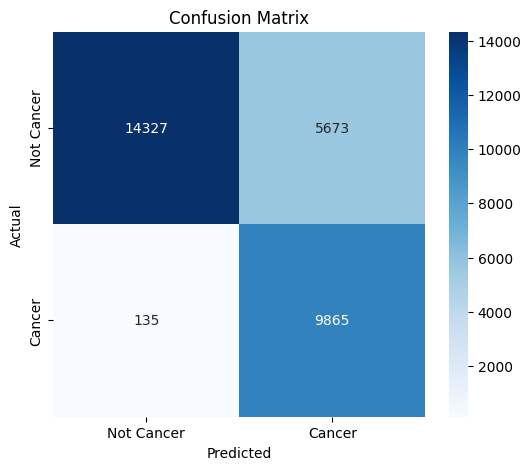


Classification Report:
              precision    recall  f1-score   support

  Not Cancer       0.99      0.72      0.83     20000
      Cancer       0.63      0.99      0.77     10000

    accuracy                           0.81     30000
   macro avg       0.81      0.85      0.80     30000
weighted avg       0.87      0.81      0.81     30000


Visualizing Top 4 'Hardest' Mistakes (Highest Loss):


NameError: name 'unnormalize_img' is not defined

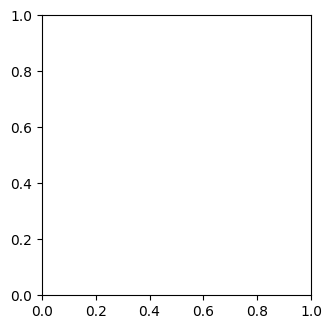

In [ ]:
# Load the best balanced weights and run analysis
model_convnext.load_state_dict(torch.load('/kaggle/working/best_convnext_6ch_model.pth'))
analyze_model_performance(model_convnext, valid_loader, device)

### Single Sample Inference: Positive Case (Cancer)
In this section, we locate a sample that is confirmed as 'Cancer' (Label 1) and see how the model evaluates it.

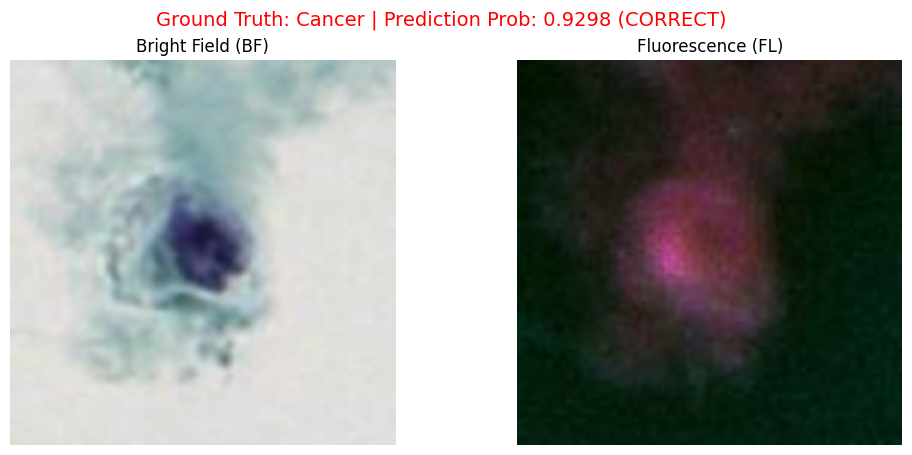

Validation Index: 20000
Final Probability: 0.9298


In [ ]:
import torch
import matplotlib.pyplot as plt

# 1. Fast Search: Find a 'Cancer' sample index using the dataframe directly
# This avoids loading/transforming every image in the dataset
cancer_df_indices = valid_ds.df[valid_ds.df['Diagnosis'] == 1].index

if len(cancer_df_indices) == 0:
    print("No cancer samples found in the current validation subset!")
else:
    # Pick the first matching index (0-indexed relative to valid_ds)
    target_idx = cancer_df_indices[0]
    bf_tensor, fl_tensor, label = valid_ds[target_idx]

    # 2. Prepare the input (6-channel for single-stream model)
    input_tensor = torch.cat([bf_tensor, fl_tensor], dim=0).unsqueeze(0).to(device)

    # 3. Model Inference
    model_convnext.eval()
    with torch.no_grad():
        output = model_convnext(input_tensor)
        prediction = torch.sigmoid(output).item()

    # 4. Helper to un-normalize
    def unnormalize_img(tensor):
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        return (tensor * std + mean).clamp(0, 1)

    # 5. Visualization
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(unnormalize_img(bf_tensor).permute(1, 2, 0))
    plt.title("Bright Field (BF)")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(unnormalize_img(fl_tensor).permute(1, 2, 0))
    plt.title("Fluorescence (FL)")
    plt.axis('off')

    status = 'CORRECT' if (prediction >= 0.5) else 'INCORRECT'
    plt.suptitle(f"Ground Truth: Cancer | Prediction Prob: {prediction:.4f} ({status})", fontsize=14, color='red')
    plt.show()

    print(f"Validation Index: {target_idx}")
    print(f"Final Probability: {prediction:.4f}")

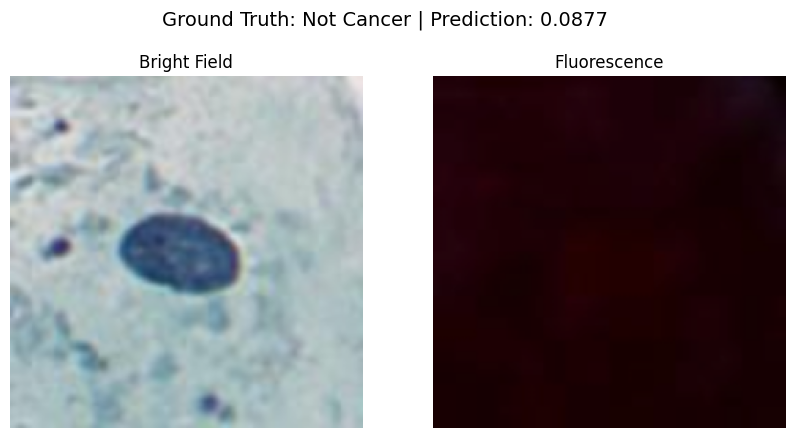

Raw Logit: -2.3420
Probability: 0.0877
Target Label: 0


In [ ]:
# 1. Pick a sample from the validation dataset
sample_idx = 3
bf_tensor, fl_tensor, label = valid_ds[sample_idx]

# 2. Prepare the input for the 6-channel model
input_tensor = torch.cat([bf_tensor, fl_tensor], dim=0).unsqueeze(0).to(device)

# 3. Model Inference
model_convnext.eval()
with torch.no_grad():
    output = model_convnext(input_tensor)
    prediction = torch.sigmoid(output).item()

# 4. Helper to un-normalize for visualization
def unnormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return (tensor * std + mean).clamp(0, 1)

# 5. Display Results
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(unnormalize(bf_tensor).permute(1, 2, 0))
plt.title("Bright Field")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(unnormalize(fl_tensor).permute(1, 2, 0))
plt.title("Fluorescence")
plt.axis('off')

plt.suptitle(f"Ground Truth: {'Cancer' if label == 1 else 'Not Cancer'} | Prediction: {prediction:.4f}", fontsize=14)
plt.show()

print(f"Raw Logit: {output.item():.4f}")
print(f"Probability: {prediction:.4f}")
print(f"Target Label: {int(label.item())}")

### Test & Submission Generation

In [ ]:
class MultimodalTestDataset(Dataset):
    def __init__(self, test_df, bf_dir, fl_dir, transform=None):
        self.df = test_df.reset_index(drop=True)
        self.bf_dir = bf_dir
        self.fl_dir = fl_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'Name']

        bf_path = os.path.join(self.bf_dir, img_name)
        bf_img = cv2.imread(bf_path)
        bf_img = cv2.cvtColor(bf_img, cv2.COLOR_BGR2RGB)

        fl_path = os.path.join(self.fl_dir, img_name)
        fl_img = cv2.imread(fl_path)
        fl_img = cv2.cvtColor(fl_img, cv2.COLOR_BGR2RGB)

        if self.transform:
            augmented = self.transform(image=bf_img, image_fl=fl_img)
            return augmented['image'], augmented['image_fl'], img_name

        bf_tensor = torch.from_numpy(bf_img).permute(2, 0, 1).float() / 255.0
        fl_tensor = torch.from_numpy(fl_img).permute(2, 0, 1).float() / 255.0
        return bf_tensor, fl_tensor, img_name

test_df = pd.read_csv(os.path.join(path, 'sampleSubmission.csv'))
BF_Test = os.path.join(path, 'BF', 'test')
FL_Test = os.path.join(path, 'FL', 'test')

test_ds = MultimodalTestDataset(test_df, BF_Test, FL_Test, transform=val_transform)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=2)

In [ ]:
# Load the best weights before inference
model_convnext.load_state_dict(torch.load('/kaggle/working/best_convnext_fold_0.pth'))
model_convnext.eval()

predictions = []
file_names = []

with torch.no_grad():
    # FIXED: Unpack all 3 items returned by MultimodalTestDataset
    for bf_imgs, fl_imgs, names in tqdm(test_loader, desc="Testing"):
        # FIXED: Concatenate images for the 6-channel single-stream model
        images = torch.cat([bf_imgs, fl_imgs], dim=1).to(device)

        with autocast("cuda"):
            outputs = model_convnext(images)

        probs = torch.sigmoid(outputs).cpu().numpy()
        predictions.extend(probs.flatten())
        file_names.extend(names)

submission = pd.DataFrame({'Name': file_names, 'Diagnosis': predictions})
submission.to_csv('submission.csv', index=False)
print("Submission file saved.")
display(submission.head())

Testing: 100%|██████████| 1845/1845 [04:05<00:00,  7.53it/s]


Submission file saved.


/usr/local/lib/python3.12/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,Name,Diagnosis
0,image_1.jpg,0.162598
1,image_2.jpg,0.098572
2,image_3.jpg,0.300781
3,image_4.jpg,0.388672
4,image_5.jpg,0.783691


In [ ]:
# # Define file paths to the 3 optimal fold checkpoints saved during training
# checkpoint_paths = [
#     "best_convnext_fold_0.pth",
#     "best_convnext_fold_1.pth",
#     "best_convnext_fold_2.pth"
# ]

# # Create a master list to aggregate prediction probabilities across folds
# # Dimensions will be: [Num_Folds, Total_Test_Images]
# all_fold_predictions = []
# file_names = []

# print(f"Starting Multi-Fold Ensemble Inference across {len(checkpoint_paths)} models...")

# # Iterate through each cross-validation checkpoint sequentially
# for fold_idx, path_to_weight in enumerate(checkpoint_paths):
#     print(f"\n---> Loading model checkpoint for Fold {fold_idx} from: {path_to_weight}")

#     # Instantiate a clean, fresh architecture for this specific checkpoint
#     model_inference = MultimodalConvNeXt().to(device)
#     model_inference.load_state_dict(torch.load(path_to_weight, map_location=device))
#     model_inference.eval()

#     fold_predictions = []
#     current_file_names = []

#     with torch.no_grad():
#         for bf_imgs, fl_imgs, names in tqdm(test_loader, desc=f"Evaluating Fold {fold_idx}"):
#             # Reconstruct the 6-channel stacked early-fusion input tensor
#             images = torch.cat([bf_imgs, fl_imgs], dim=1).to(device)

#             with autocast("cuda"):
#                 outputs = model_inference(images)

#             # Convert raw model logit scalar outputs to bounded probabilities [0.0, 1.0]
#             probs = torch.sigmoid(outputs).cpu().numpy()
#             fold_predictions.extend(probs.flatten())

#             # Record file names on the first pass to preserve alignment integrity
#             if fold_idx == 0:
#                 file_names.extend(names)

#     # Append the flattened probability vector for this model checkpoint
#     all_fold_predictions.append(fold_predictions)

# # =====================================================================
# # MATHEMATICAL BLENDING & SUBMISSION GENERATION
# # =====================================================================

# # Convert master list to an organized 2D NumPy Array
# # Shape will be: (3, Num_Test_Images)
# predictions_matrix = np.array(all_fold_predictions)

# # Calculate the mean probability score along the vertical fold column dimension (axis=0)
# averaged_ensemble_probabilities = np.mean(predictions_matrix, axis=0)

# # Build the finalized delivery DataFrame
# submission = pd.DataFrame({
#     'Name': file_names,
#     'Diagnosis': averaged_ensemble_probabilities
# })

# # Crucial sanity step: Map the predictions explicitly back onto the original
# # sample submission sequence to prevent grading misalignments due to system sorting rules
# sample_sub_template = pd.read_csv(os.path.join(path, 'sampleSubmission.csv'))

# # Update the 'Diagnosis' column in the exact sorting index layout requested by Kaggle
# sample_sub_template['Diagnosis'] = sample_sub_template['Name'].map(
#     submission.set_index('Name')['Diagnosis']
# )

# # Export out to disk in the working output path space
# sample_sub_template.to_csv('submission.csv', index=False)
# print("\n" + "="*50)
# print("SUCCESS: Ensembled submission.csv file successfully generated and verified.")
# print("="*50)

# # Display head of final submission array to check confidence bounds
# display(sample_sub_template.head(10))

Starting Multi-Fold Ensemble Inference across 3 models...

---> Loading model checkpoint for Fold 0 from: best_convnext_fold_0.pth


Evaluating Fold 0: 100%|██████████| 1845/1845 [09:46<00:00,  3.14it/s]



---> Loading model checkpoint for Fold 1 from: best_convnext_fold_1.pth


FileNotFoundError: [Errno 2] No such file or directory: 'best_convnext_fold_1.pth'

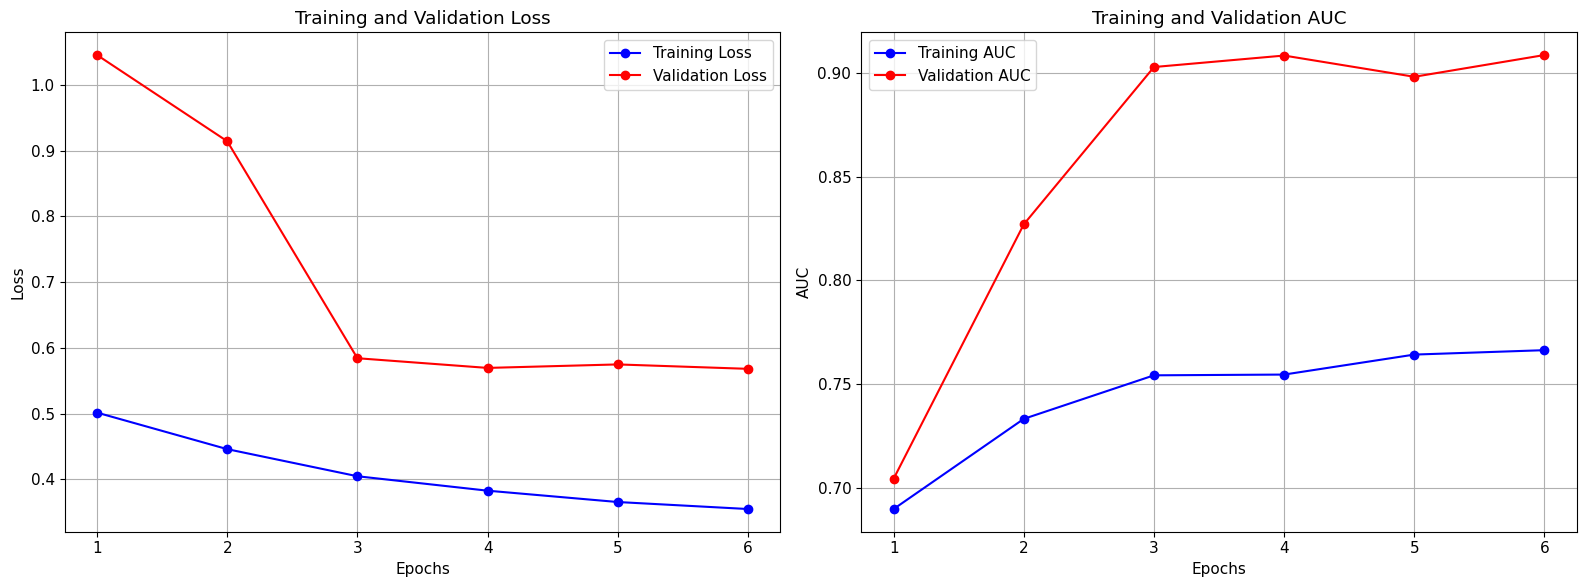

In [ ]:
import matplotlib.pyplot as plt

# Extract history from the fold_history dictionary
train_auc = fold_history['train_auc']
val_auc = fold_history['val_auc']
train_loss = fold_history['train_loss']
val_loss = fold_history['val_loss']
epochs = range(1, len(train_auc) + 1)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))



# Plot Loss
ax[0].plot(epochs, train_loss, 'bo-', label='Training Loss')
ax[0].plot(epochs, val_loss, 'ro-', label='Validation Loss')
ax[0].set_title('Training and Validation Loss')
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('Loss')
ax[0].legend()
ax[0].grid(True)

# Plot AUC
ax[1].plot(epochs, train_auc, 'bo-', label='Training AUC')
ax[1].plot(epochs, val_auc, 'ro-', label='Validation AUC')
ax[1].set_title('Training and Validation AUC')
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('AUC')
ax[1].legend()
ax[1].grid(True)






plt.tight_layout()
plt.savefig('learningCurve.png')
plt.show()

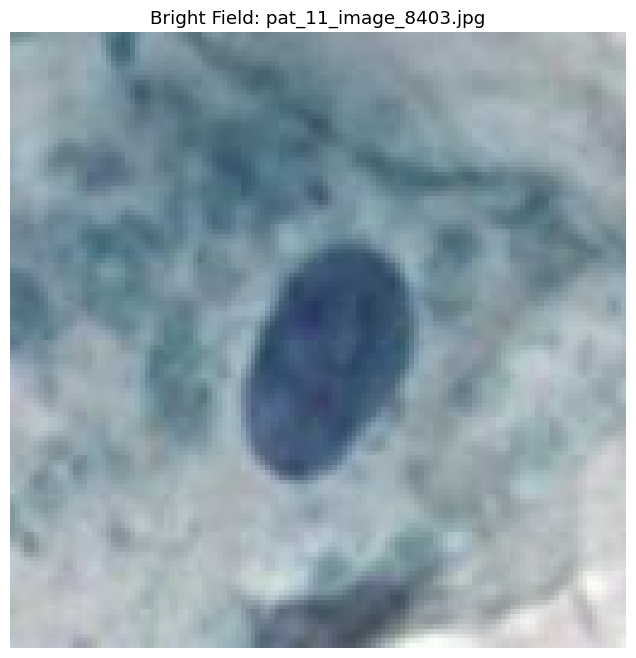

In [ ]:
import random
import matplotlib.pyplot as plt
import os
import cv2

# Select a random image name
random_img_name = random.choice(BF_Images_list)
bf_path = os.path.join(BF_Images, random_img_name)

# Display Bright Field Image
bf_img = cv2.cvtColor(cv2.imread(bf_path), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 8))
plt.imshow(bf_img)
plt.title(f"Bright Field: {random_img_name}")
plt.axis('off')
plt.show()

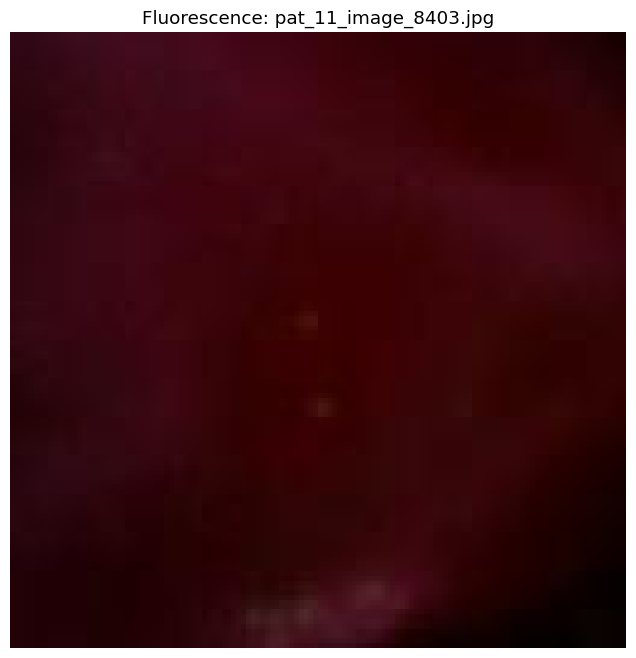

In [ ]:
# Use the same image name for consistency in the second cell
fl_path = os.path.join(FL_Images, random_img_name)

# Display Fluorescence Image
fl_img = cv2.cvtColor(cv2.imread(fl_path), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 8))
plt.imshow(fl_img)
plt.title(f"Fluorescence: {random_img_name}")
plt.axis('off')
plt.show()